In [1]:
from pyspecdata import find_file, plot
from matplotlib.pyplot import (
    text,
    axvline,
    figure,
    legend,
    savefig,
    rcParams,
    gca,
    show,
)

**Warning!** I'm hacking the sqrt behavior of pint.  Consider using the jmfranck/pint fork


In [25]:
# load file
d = {}  # dictionary of nddata
for k, fname in [
    # 2nd Synthesis
    (
        "d_TEMPO_SO4_20mM_w1_Syn2",
        "250113_20mM_TSO4_W1_Syn2.DSC"
        # Sample name: 20 mM TEMPO-SO4 in isooctane w0=1 (2nd Synthesis)
    ),
    (
        "d_TEMPO_SO4_20mM_w3_Syn2",
        "250113_20mM_TSO4_W3_Syn2.DSC"
        # Sample name: 20 mM TEMPO-SO4 in isooctane w0=3 (2nd Synthesis)
    ),
]:
    d[k] = find_file(fname, exp_type="francklab_esr/romana")
    d[k] = d[k].chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]
    

# 2nd Synthesis vs previous synthesis

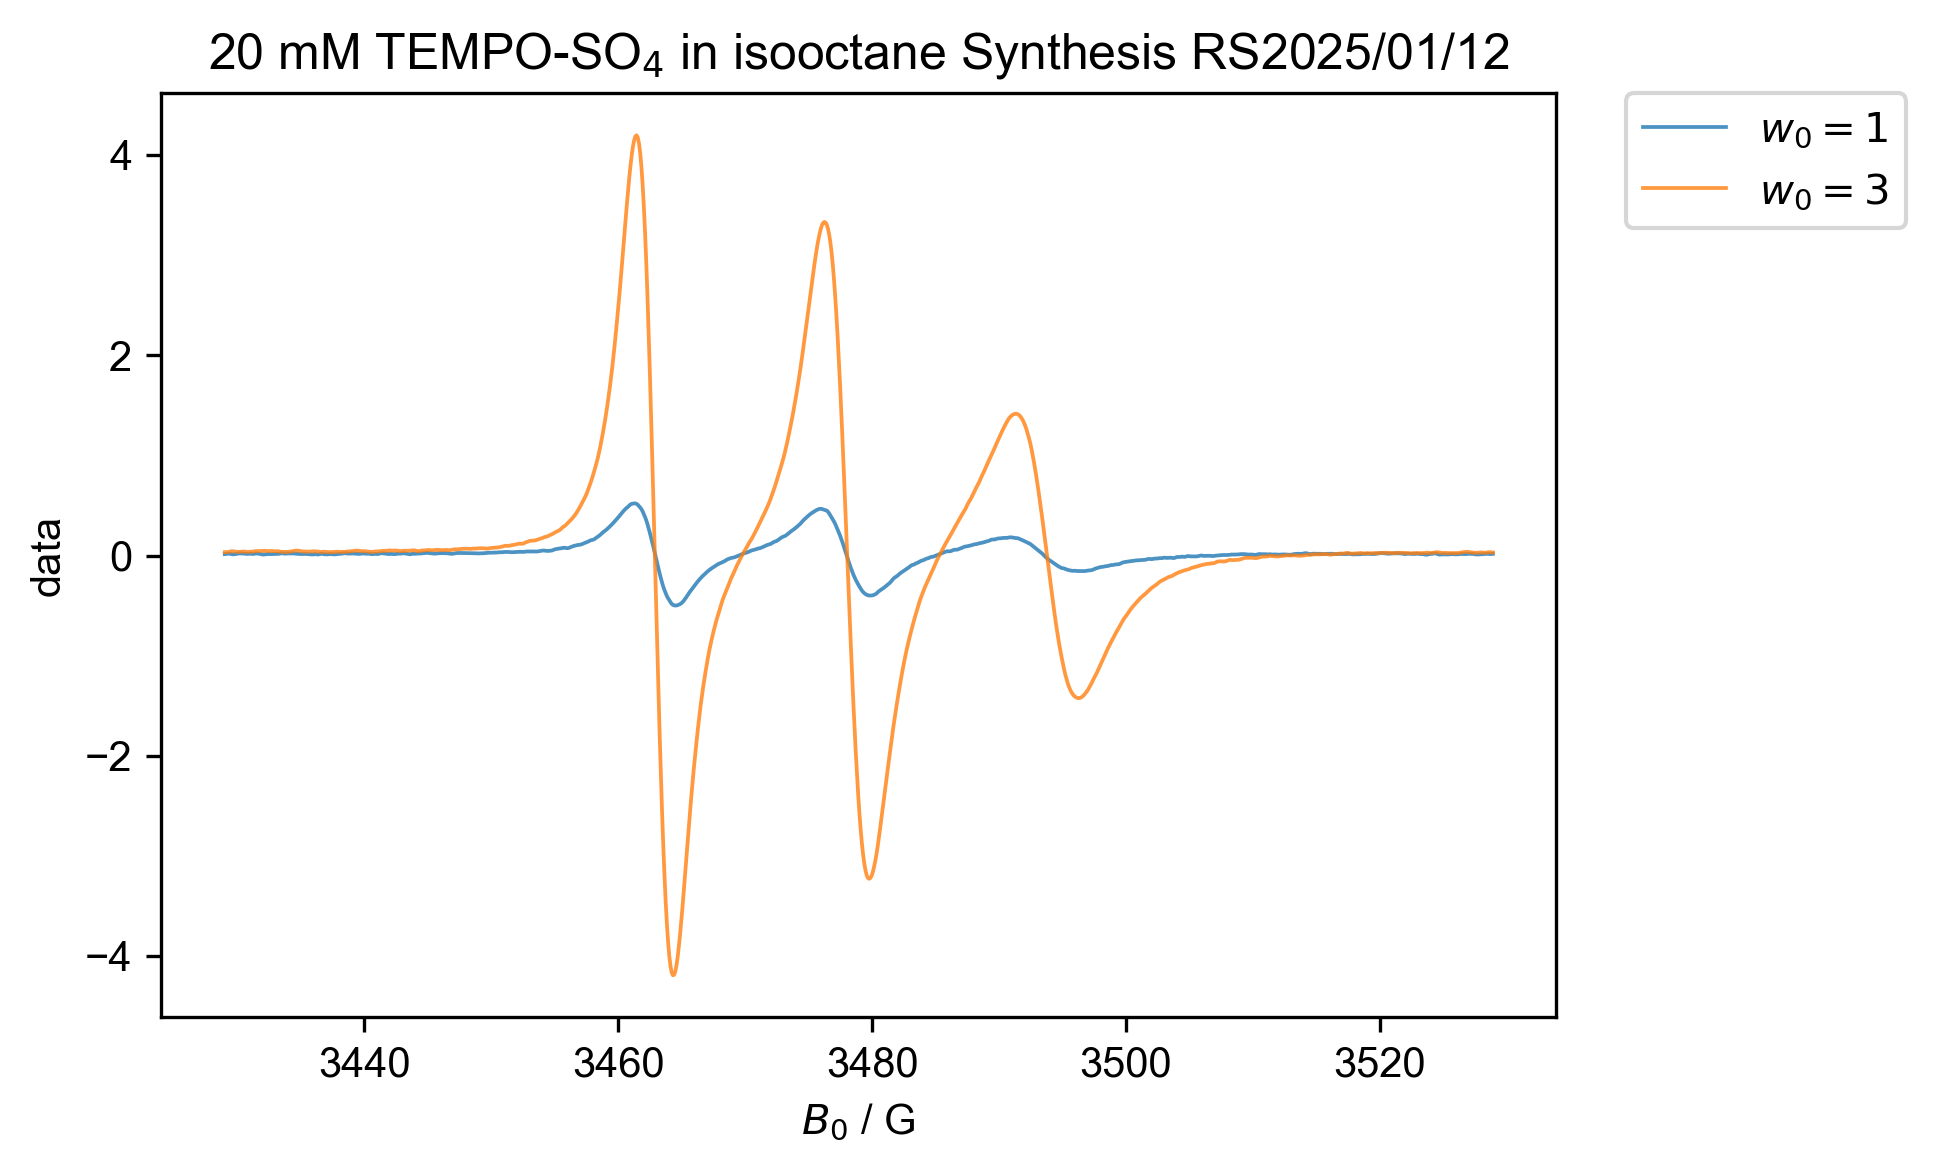

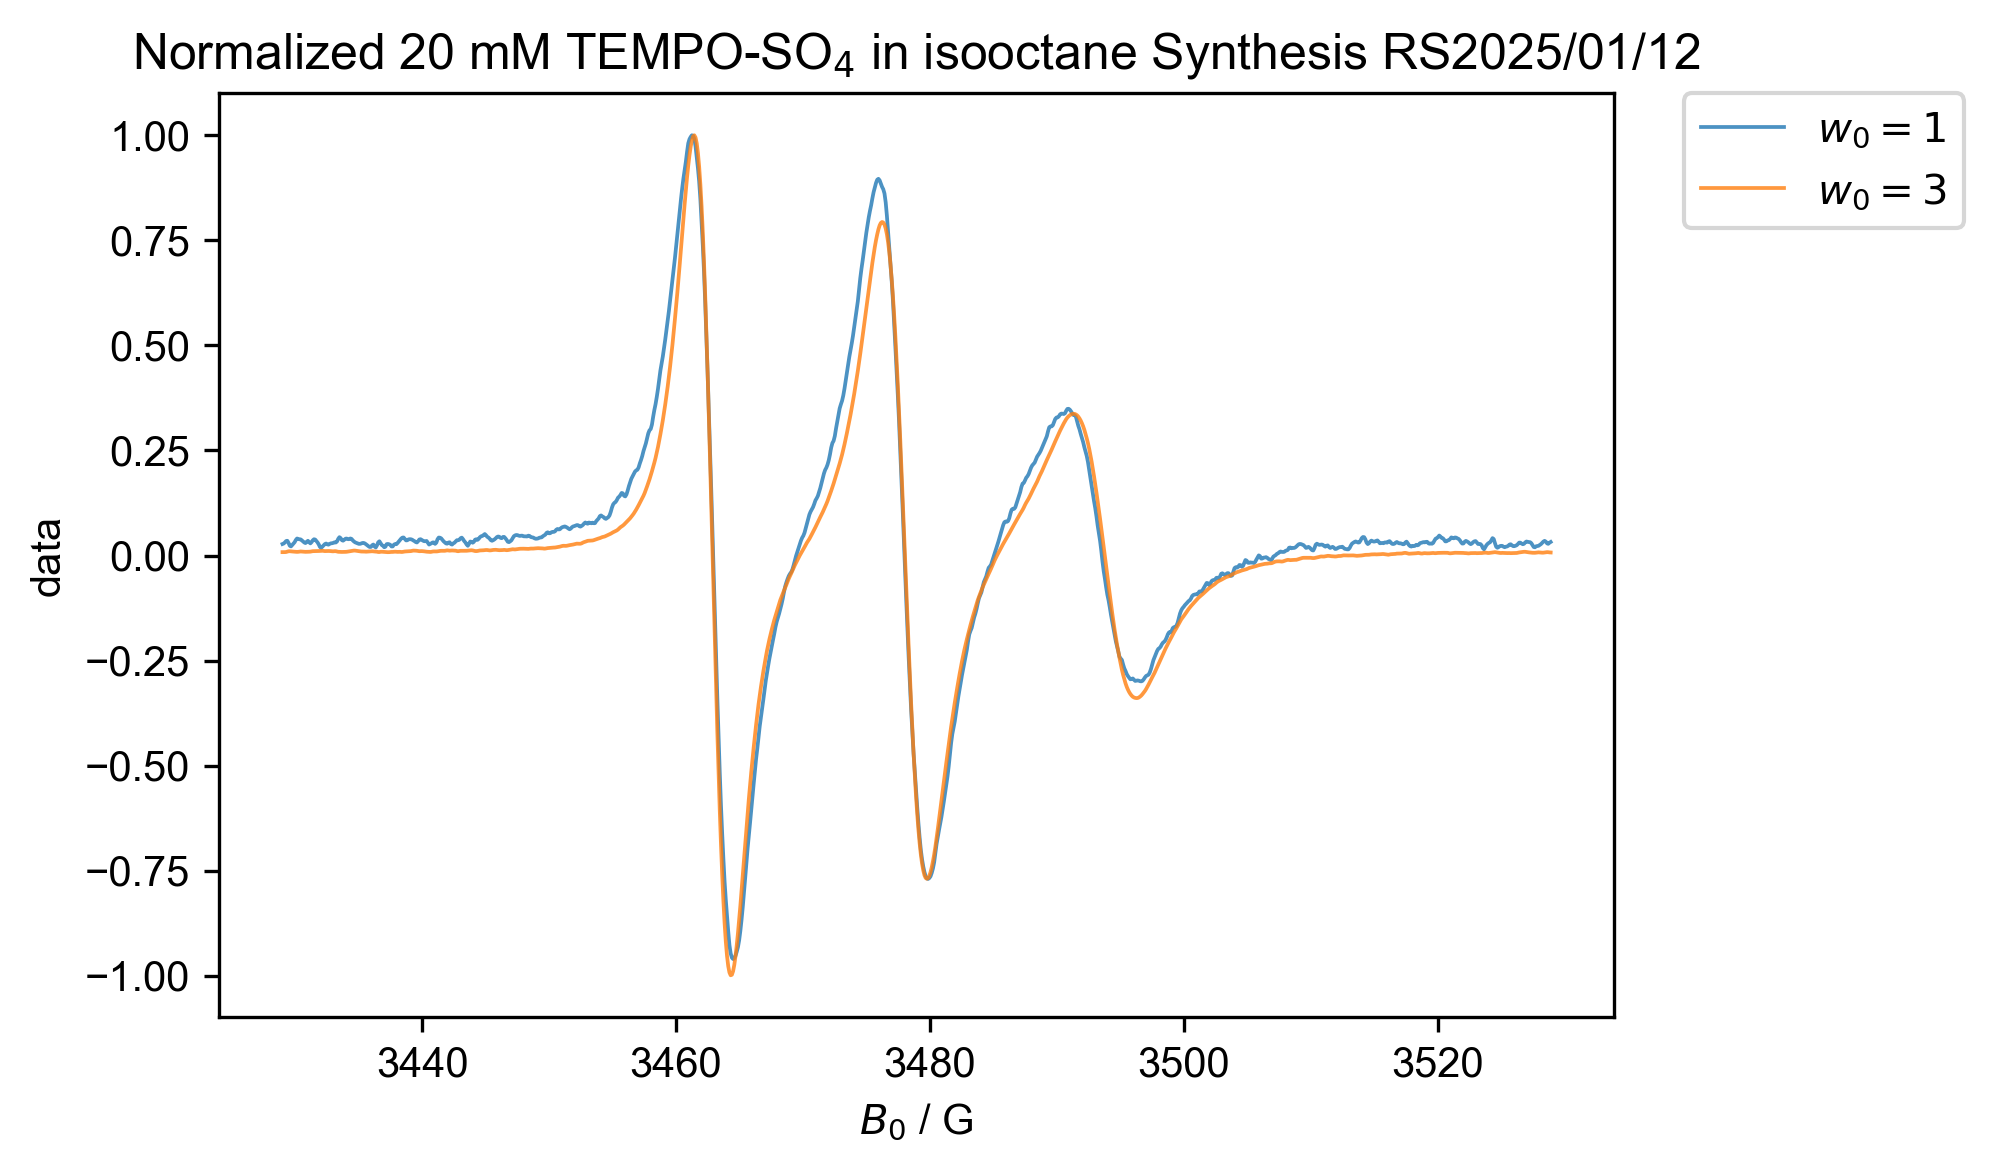

In [14]:
# TEMPO-SO4 20 mM
figure(dpi=300, figsize=(6,4)),
for k, thislabel in [
    ("d_TEMPO_SO4_20mM_w1_Syn2", "$w_0=1$"),
    ("d_TEMPO_SO4_20mM_w3_Syn2", "$w_0=3$"),

]:
    d[k] = d[k]["$B_0$":(3400, 3550)]
    plot(
        d[k],
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
gca().set_title("20 mM TEMPO-SO$_4$ in isooctane Synthesis RS2025/01/12"),
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside

# normalized
figure(dpi=300, figsize=(6,4)),
for k, thislabel in [
    ("d_TEMPO_SO4_20mM_w1_Syn2", "$w_0=1$"),
    ("d_TEMPO_SO4_20mM_w3_Syn2", "$w_0=3$"),
]:
    d[k] = d[k]["$B_0$":(3400, 3550)]
    plot(
        d[k]/d[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
gca().set_title("Normalized 20 mM TEMPO-SO$_4$ in isooctane Synthesis RS2025/01/12"),
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside

# load previous data w3

In [26]:
d_w3_old = find_file("240220_TempoSO4_W3.DSC", exp_type = "francklab_esr/romana") # previous w3 temperature dependant spectra cooling TSO4 in isooctane
d_w3_old = d_w3_old.chunk_auto("harmonic","harmonic")["harmonic",0]["phase",0]
d_w3_old.reorder("Temperature").sort("Temperature")
# d_w3_old.pcolor()

array([[ 0.0018417 , -0.00154008, -0.00337451, ..., -0.04062795,
        -0.03961163, -0.03460572],
       [ 0.00414274,  0.00281018, -0.00117136, ..., -0.02963593,
        -0.02828906, -0.03100201],
       [-0.00286381, -0.00608072, -0.01139681, ..., -0.02670192,
        -0.02450592, -0.01880851],
       ...,
       [-0.01577076, -0.01510729, -0.00656058, ..., -0.00716451,
        -0.0077967 , -0.00940687],
       [-0.00825787, -0.00800164, -0.00591392, ..., -0.01323473,
        -0.01107337, -0.00669359],
       [ 0.00803076,  0.00808055,  0.01196574, ...,  0.00740973,
         0.00897391,  0.00863132]], dtype='>f8')
		+/-None
	dimlabels=['Temperature', '$B_0$']
	axes={`Temperature':array([213.565, 223.612, 233.819, 243.863, 252.461, 262.57 , 272.297,
       282.495, 292.354, 302.071], dtype='>f8')
			+/-None,
		`$B_0$':array([3310.        , 3310.09765625, 3310.1953125 , ..., 3409.7070315 ,
       3409.80468775, 3409.902344  ])
			+/-None}

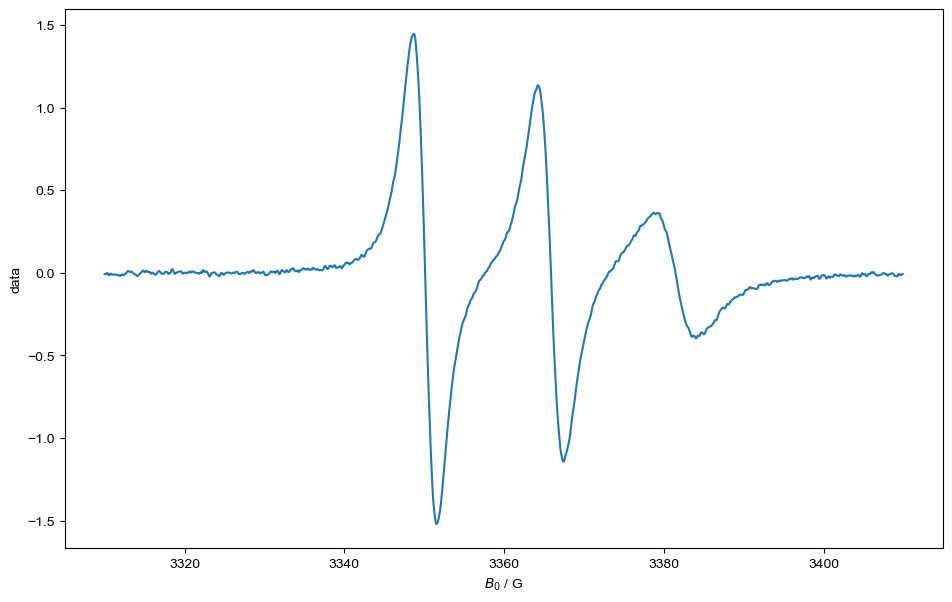

[213.565 223.612 233.819 243.863 252.461 262.57  272.297 282.495 292.354
 302.071]


In [11]:
plot(d_w3_old["Temperature":(293)])
show()
print(d_w3_old.getaxis("Temperature"))

## compare data

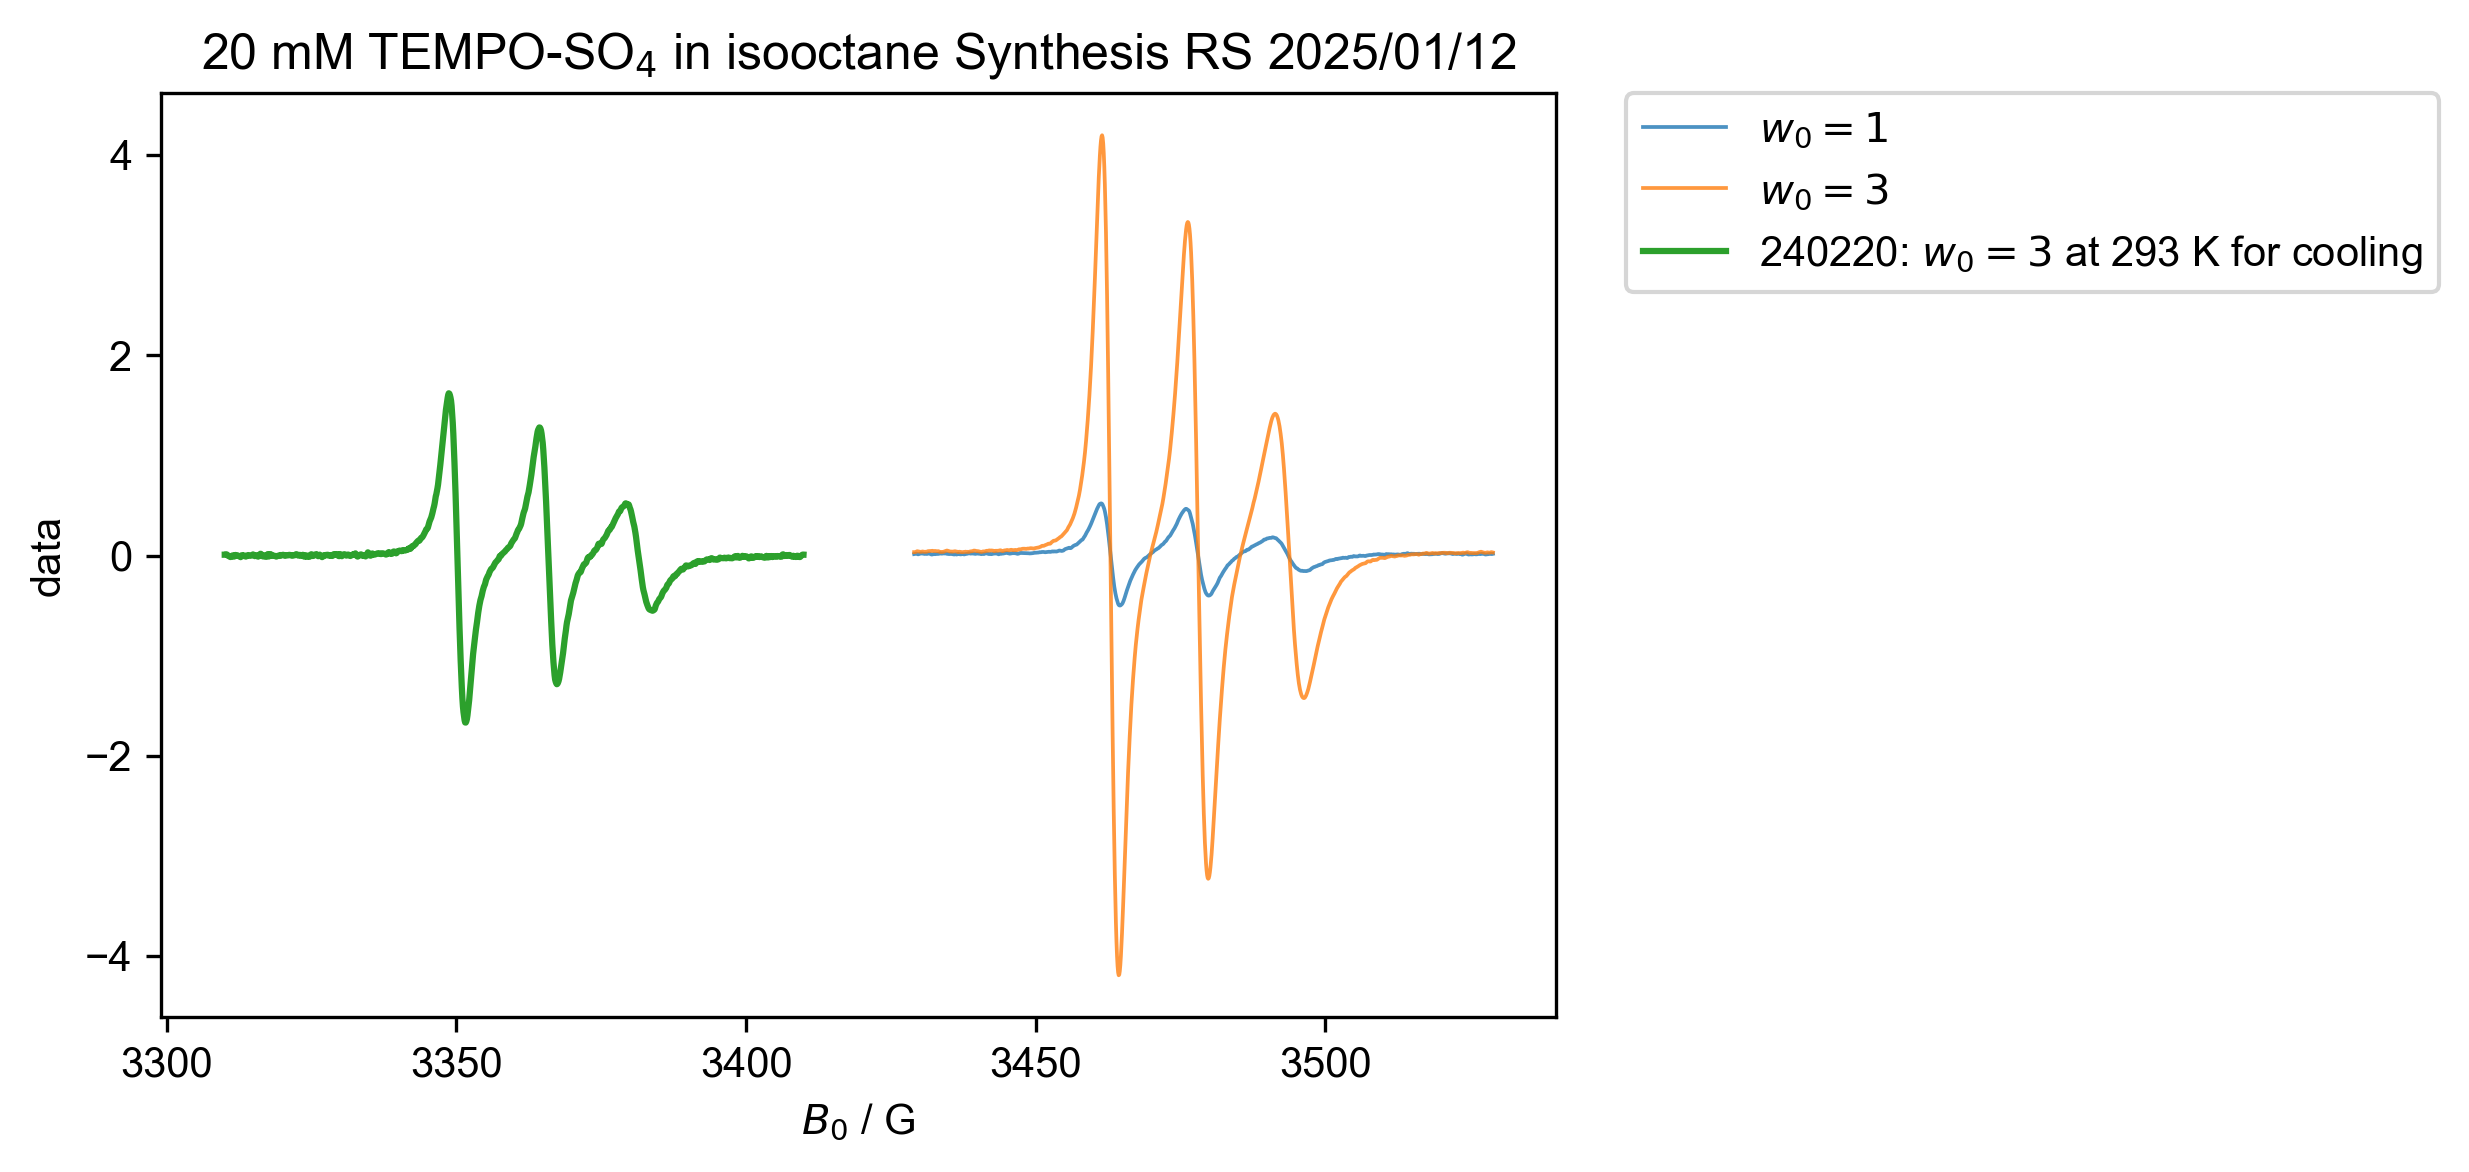

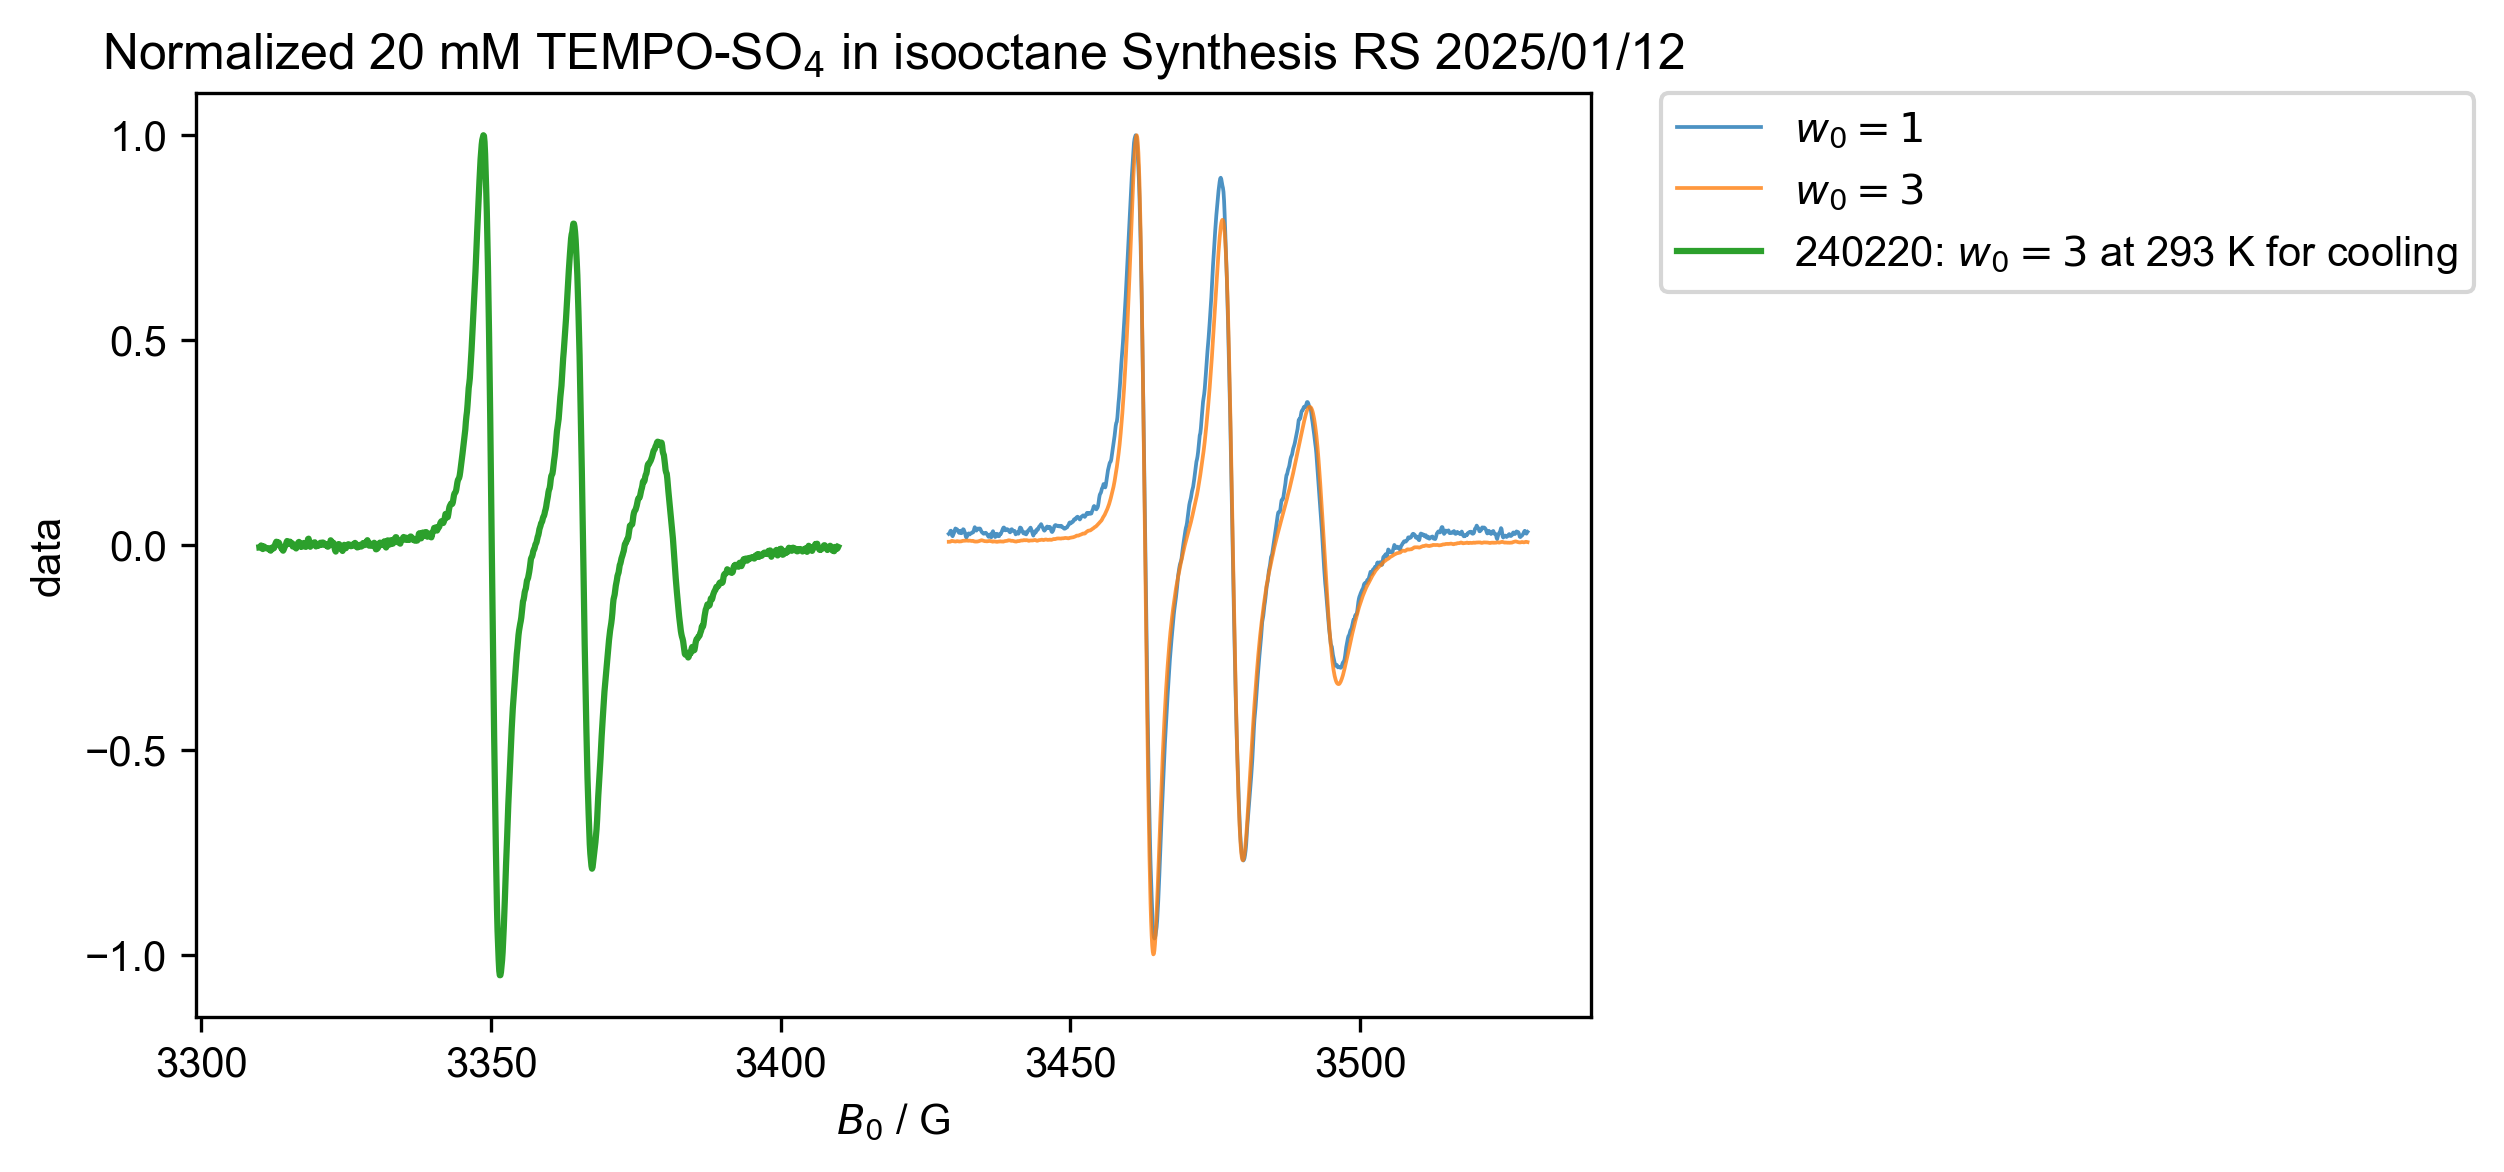

In [13]:
# TEMPO-SO4 20 mM
figure(dpi=300, figsize=(6,4)),
for k, thislabel in [
    ("d_TEMPO_SO4_20mM_w1_Syn2", "$w_0=1$"),
    ("d_TEMPO_SO4_20mM_w3_Syn2", "$w_0=3$"),

]:
    d[k] = d[k]["$B_0$":(3400, 3550)]
    plot(
        d[k],
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
plot(d_w3_old["Temperature":(298)], label= "240220 data $w_0=3$ at 293 K for cooling")
# show()
gca().set_title("20 mM TEMPO-SO$_4$ in isooctane Synthesis RS 2025/01/12"),
legend(
     bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside

# normalized
figure(dpi=300, figsize=(6,4)),
for k, thislabel in [
    ("d_TEMPO_SO4_20mM_w1_Syn2", "$w_0=1$"),
    ("d_TEMPO_SO4_20mM_w3_Syn2", "$w_0=3$"),
]:
    d[k] = d[k]["$B_0$":(3400, 3550)]
    plot(
        d[k]/d[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
plot(d_w3_old["Temperature":293] / d_w3_old["Temperature":293].max(), label= "240220 data $w_0=3$ at 293 K for cooling")
# show()
gca().set_title("Normalized 20 mM TEMPO-SO$_4$ in isooctane Synthesis RS 2025/01/12"),
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside

3475.9465648137534
3476.2328243553006
3364.1992188856307


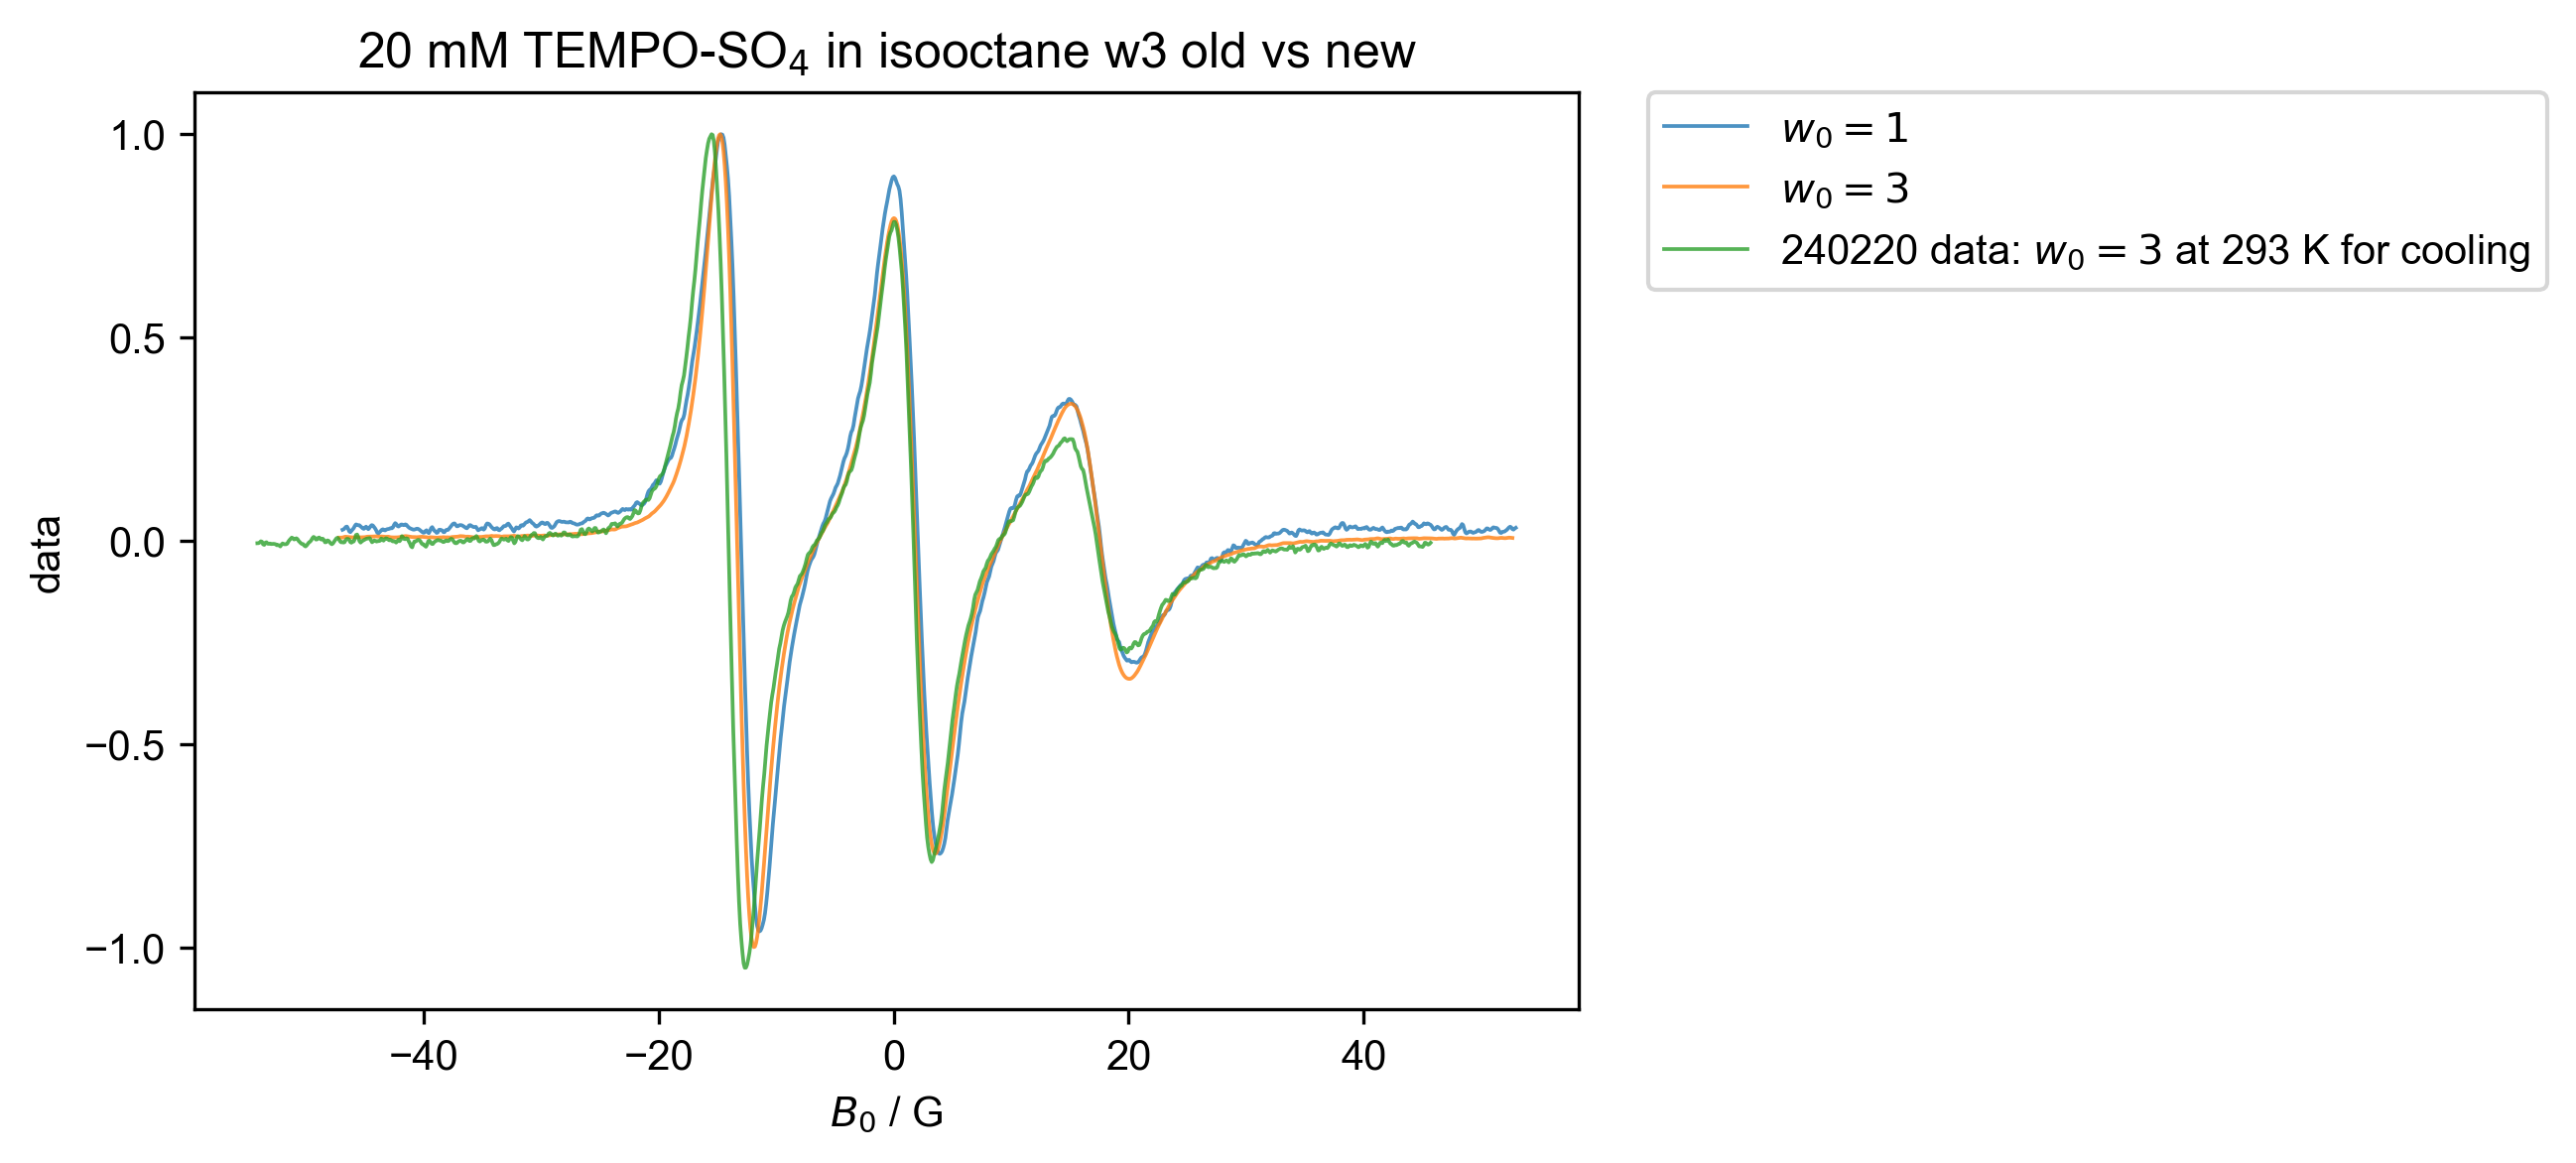

In [27]:
# TEMPO-SO4 20 mM
figure(dpi=300, figsize=(6,4)),
for k, thislabel in [
    ("d_TEMPO_SO4_20mM_w1_Syn2", "$w_0=1$"),
    ("d_TEMPO_SO4_20mM_w3_Syn2", "$w_0=3$"),

]:
    d[k] = d[k]["$B_0$":(3400, 3550)]
    thismax= d[k]["$B_0$":(3470, 3490)].C.argmax().item()
    print(thismax)
    d[k]["$B_0$"]-=thismax
    plot(
        d[k]/d[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
# old data
thismax_w3_old= d_w3_old["$B_0$":(3360, 3375)]["Temperature":293].C.argmax().item()
print(thismax_w3_old)
d_w3_old["$B_0$"]-=thismax_w3_old
plot(d_w3_old["Temperature":293] / d_w3_old["Temperature":293].max(), label="240220 data: $w_0=3$ at 293 K for cooling", alpha=0.8, lw=0.9)
gca().set_title("20 mM TEMPO-SO$_4$ in isooctane w3 old vs new"),
legend(
     bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside

In [ ]:
thismax= d[k]["$B_0$":(3470, 3490)].C.argmax().item()
    print(thismax)
    d[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d[k]/d[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )